In [94]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [95]:
import os
import sys

# Navigates up one level from 'notebooks' and enters 'src'
src_path = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
if src_path not in sys.path:
    sys.path.append(src_path)

# Now you can import directly from data_loader
from data.data_loader import price, production

In [96]:
print(price.shape)
print(production.shape)

(120298, 32)
(233715, 31)


In [97]:
from forecasting.price_forecast import forecast_prices
from forecasting.production_forecast import forecast_production

In [98]:
print(forecast_prices)
print(forecast_production)

<function forecast_prices at 0x00000239F9F409E0>
<function forecast_production at 0x00000239F9F41010>


In [99]:
def get_candidate_crops(
    state,
    district,
    season
):

    candidate_crops = (

        production[
            (production["State"] == state)
            &
            (production["District_Name"] == district)
            &
            (production["Season"] == season)
        ]

        ["Crop"]

        .dropna()

        .unique()

    )

    return sorted(candidate_crops)

In [100]:
candidate_crops = get_candidate_crops(

    state="Andhra Pradesh",

    district="Anantapur",

    season="Kharif"

)

print(candidate_crops)
print(len(candidate_crops))

['Arecanut', 'Arhar/Tur', 'Bajra', 'Brinjal', 'Cabbage', 'Cashewnut', 'Castor Seed', 'Coriander', 'Cotton(Lint)', 'Cowpea(Lobia)', 'Dry Chillies', 'Gram', 'Grapes', 'Groundnut', 'Horse-Gram', 'Jowar', 'Korra', 'Lemon', 'Linseed', 'Maize', 'Mango', 'Mesta', 'Moong(Green Gram)', 'Onion', 'Other Kharif Pulses', 'Other Oilseeds', 'Papaya', 'Pome Granet', 'Potato', 'Ragi', 'Rice', 'Samai', 'Sapota', 'Sesamum', 'Small Millets', 'Soyabean', 'Sugarcane', 'Sunflower', 'Tobacco', 'Tomato', 'Turmeric', 'Urad']
42


In [101]:
def get_price_weather(
    state,
    crop,
    start_year,
    start_month,
    months
):

    history = price[
        (price["State"] == state) &
        (price["Standard_Crop"] == crop)
    ].copy()

    if history.empty:
        raise ValueError(
            f"No price history found for {crop} in {state}"
        )

    # Average weather for each month
    monthly_weather = (
        history.groupby("Month")[
            [
                "Avg_Temperature_C",
                "Avg_DewPoint_C",
                "Avg_Rainfall_mm",
                "Avg_Wind_Speed",
                "Avg_Surface_Pressure_hPa"
            ]
        ]
        .mean()
        .reset_index()
    )

    weather_rows = []

    year = start_year
    month = start_month

    for _ in range(months):

        row = monthly_weather[
            monthly_weather["Month"] == month
        ].iloc[0]

        weather_rows.append({
            "Avg_Temperature_C": row["Avg_Temperature_C"],
            "Avg_DewPoint_C": row["Avg_DewPoint_C"],
            "Avg_Rainfall_mm": row["Avg_Rainfall_mm"],
            "Avg_Wind_Speed": row["Avg_Wind_Speed"],
            "Avg_Surface_Pressure_hPa": row["Avg_Surface_Pressure_hPa"]
        })

        month += 1

        if month == 13:
            month = 1
            year += 1

    return pd.DataFrame(weather_rows)

In [102]:
price_weather = get_price_weather(
    state="Andhra Pradesh",
    crop="Groundnut",
    start_year=2016,
    start_month=1,
    months=24
)

price_weather.head()

,Avg_Temperature_C,Avg_DewPoint_C,Avg_Rainfall_mm,Avg_Wind_Speed,Avg_Surface_Pressure_hPa
0,23.463265,16.693663,0.213359,1.570405,984.326887
1,25.564160,16.774282,0.309098,1.645878,982.852528
2,28.378786,18.529679,0.558633,1.818741,981.040864
3,30.539907,21.060028,0.775352,1.788031,978.741130
4,31.767473,21.859676,1.655434,1.851218,975.432063


In [103]:
def get_production_weather(
    state,
    district,
    crop,
    season,
    start_year,
    years
):

    history = production[
        (production["State"] == state) &
        (production["District_Name"] == district) &
        (production["Crop"] == crop) &
        (production["Season"] == season)
    ].copy()

    if history.empty:
        raise ValueError(
            f"No production history found for {crop}"
        )

    avg_weather = {
        "Avg_Annual_Temperature":
            history["Avg_Annual_Temperature"].mean(),

        "Avg_Annual_DewPoint":
            history["Avg_Annual_DewPoint"].mean(),

        "Total_Annual_Rainfall":
            history["Total_Annual_Rainfall"].mean(),

        "Avg_Annual_Wind_Speed":
            history["Avg_Annual_Wind_Speed"].mean(),

        "Avg_Annual_Surface_Pressure":
            history["Avg_Annual_Surface_Pressure"].mean()
    }

    weather = pd.DataFrame(
        [avg_weather] * years
    )

    return weather

In [104]:
production_weather = get_production_weather(
    state="Andhra Pradesh",
    district="Anantapur",
    crop="Groundnut",
    season="Kharif",
    start_year=2016,
    years=5
)

production_weather

,Avg_Annual_Temperature,Avg_Annual_DewPoint,Total_Annual_Rainfall,Avg_Annual_Wind_Speed,Avg_Annual_Surface_Pressure
0,27.356057,20.298377,31.058372,2.070659,979.054968
1,27.356057,20.298377,31.058372,2.070659,979.054968
2,27.356057,20.298377,31.058372,2.070659,979.054968
3,27.356057,20.298377,31.058372,2.070659,979.054968
4,27.356057,20.298377,31.058372,2.070659,979.054968


In [105]:
print(price_weather.shape)
print(production_weather.shape)

(24, 5)
(5, 5)


In [106]:
def annualize_price_forecast(price_forecast):

    annual_price = (
        price_forecast
        .groupby("Year", as_index=False)["Predicted_Price"]
        .mean()
        .rename(
            columns={
                "Predicted_Price": "Average_Price"
            }
        )
    )

    return annual_price

### Testing

In [107]:
price_weather = get_price_weather(
    state="Andhra Pradesh",
    crop="Groundnut",
    start_year=2016,
    start_month=1,
    months=36
)

price_forecast, _ = forecast_prices(
    state="Andhra Pradesh",
    crop="Groundnut",
    start_year=2016,
    start_month=1,
    months=36,
    weather_data=price_weather
)

annual_price = annualize_price_forecast(price_forecast)

annual_price

,Year,Average_Price
0,2016,3938.187483
1,2017,3949.126459
2,2018,3947.784659


In [108]:
def calculate_expected_revenue(
    annual_price,
    production_forecast
):

    revenue = annual_price.merge(

        production_forecast[
            [
                "Year",
                "Predicted_Production"
            ]
        ],

        on="Year",

        how="inner"

    )

    revenue["Expected_Revenue"] = (

        revenue["Average_Price"]

        *

        revenue["Predicted_Production"]

    )

    return revenue

### Testing

In [109]:
production_weather = get_production_weather(
    state="Andhra Pradesh",
    district="Anantapur",
    crop="Groundnut",
    season="Kharif",
    start_year=2016,
    years=3
)

production_forecast, _ = forecast_production(
    state="Andhra Pradesh",
    district="Anantapur",
    crop="Groundnut",
    season="Kharif",
    area=100,
    start_year=2016,
    years=3,
    weather_data=production_weather
)

revenue = calculate_expected_revenue(
    annual_price,
    production_forecast
)

revenue

,Year,Average_Price,Predicted_Production,Expected_Revenue
0,2016,3938.187483,241.073636,9.493932e+05
1,2017,3949.126459,270.361053,1.067690e+06
2,2018,3947.784659,259.281611,1.023588e+06


### Evaluate one crop

In [110]:
def evaluate_crop(
    state,
    district,
    crop,
    season,
    area,
    start_year,
    years
):

    # -----------------------------------
    # Generate Weather Forecast
    # -----------------------------------

    price_weather = get_price_weather(
        state=state,
        crop=crop,
        start_year=start_year,
        start_month=1,
        months=years * 12
    )

    production_weather = get_production_weather(
        state=state,
        district=district,
        crop=crop,
        season=season,
        start_year=start_year,
        years=years
    )

    # -----------------------------------
    # Forecast Price
    # -----------------------------------

    price_forecast, _ = forecast_prices(
        state=state,
        crop=crop,
        start_year=start_year,
        start_month=1,
        months=years * 12,
        weather_data=price_weather
    )

    # -----------------------------------
    # Forecast Production
    # -----------------------------------

    production_forecast, _ = forecast_production(
        state=state,
        district=district,
        crop=crop,
        season=season,
        area=area,
        start_year=start_year,
        years=years,
        weather_data=production_weather
    )

    # -----------------------------------
    # Annual Price
    # -----------------------------------

    annual_price = annualize_price_forecast(
        price_forecast
    )

    # -----------------------------------
    # Revenue Table
    # -----------------------------------

    revenue_table = calculate_expected_revenue(
        annual_price,
        production_forecast
    )

    # -----------------------------------
    # Average Values
    # -----------------------------------

    average_price = annual_price[
        "Average_Price"
    ].mean()

    average_production = production_forecast[
        "Predicted_Production"
    ].mean()

    average_revenue = (
        average_price *
        average_production
    )

    # -----------------------------------
    # Yield Validation
    # -----------------------------------

    predicted_yield = (
        average_production / area
        if area > 0
        else np.nan
    )

    historical = production[
        (production["State"] == state) &
        (production["District_Name"] == district) &
        (production["Crop"] == crop) &
        (production["Season"] == season)
    ].copy()

    if historical.empty:

        historical_max_yield = np.nan
        yield_ratio = np.nan
        yield_warning = False

    else:

        historical["Yield"] = (
            historical["Production"] /
            historical["Area"]
        )

        historical_max_yield = historical[
            "Yield"
        ].max()

        yield_ratio = (
            predicted_yield /
            historical_max_yield
            if historical_max_yield > 0
            else np.nan
        )

        yield_warning = (
            predicted_yield >
            historical_max_yield * 1.20
        )

    # -----------------------------------
    # Return Results
    # -----------------------------------

    return {

        "Crop": crop,

        "Average_Price": average_price,

        "Average_Production": average_production,

        "Average_Revenue": average_revenue,

        "Revenue_Table": revenue_table,

        "Predicted_Yield": predicted_yield,

        "Historical_Max_Yield": historical_max_yield,

        "Yield_Ratio": yield_ratio,

        "Yield_Warning": yield_warning,

        "Price_Forecast": price_forecast,

        "Production_Forecast": production_forecast

    }

In [111]:
result = evaluate_crop(
    state="Andhra Pradesh",
    district="Anantapur",
    crop="Dry Chillies",
    season="Kharif",
    area=100,
    start_year=2016,
    years=3
)

print(result["Average_Price"])
print(result["Average_Production"])
print(result["Average_Revenue"])

result["Revenue_Table"]

8846.989432448485
565.5640661497733
5003539.316599641


,Year,Average_Price,Predicted_Production,Expected_Revenue
0,2016,8888.063409,529.097989,4.702656e+06
1,2017,8826.452444,612.080906,5.402503e+06
2,2018,8826.452444,555.513303,4.903212e+06


In [112]:
price[
    (price["State"] == "Andhra Pradesh") &
    (price["Standard_Crop"] == "Dry Chillies")
][
    ["Year", "Month", "Avg_Modal_Price"]
].describe()

,Year,Month,Avg_Modal_Price
count,136.000000,136.000000,136.000000
mean,2009.823529,6.558824,4830.751323
std,3.288324,3.470008,1721.872608
min,2004.000000,1.000000,1348.000000
25%,2007.000000,4.000000,3890.816327
50%,2010.000000,6.500000,4510.931174
75%,2013.000000,10.000000,6169.400680
max,2015.000000,12.000000,9231.516667


In [113]:
production[
    (production["State"] == "Andhra Pradesh") &
    (production["District_Name"] == "Anantapur") &
    (production["Crop"] == "Dry Chillies") &
    (production["Season"] == "Kharif")
][
    ["Year", "Area", "Production"]
]

,Year,Area,Production
2093,1998,4000.0,10000.0
2130,2000,3755.0,10146.0
2156,2001,3765.0,7127.0
2182,2002,2737.0,6128.0
2208,2003,2920.0,10702.0
2234,2004,3402.0,11288.0
2260,2005,2178.0,6175.0
2286,2006,1754.0,5658.0
2312,2007,2000.0,9000.0
2333,2008,1574.0,5506.0


In [114]:
production[
    (production["State"] == "Andhra Pradesh") &
    (production["District_Name"] == "Anantapur") &
    (production["Crop"] == "Dry Chillies") &
    (production["Season"] == "Kharif")
]["Production"].describe()

count       16.000000
mean      7806.812500
std       2650.406666
min       3965.000000
25%       5644.250000
50%       7217.000000
75%      10215.750000
max      11848.000000
Name: Production, dtype: float64

In [115]:
production["Yield"] = production["Production"] / production["Area"]

In [116]:
production[
    (production["State"] == "Andhra Pradesh") &
    (production["District_Name"] == "Anantapur") &
    (production["Crop"] == "Dry Chillies") &
    (production["Season"] == "Kharif")
]["Yield"].describe()

count    16.000000
mean      2.932679
std       0.849654
min       1.497922
25%       2.434737
50%       2.768584
75%       3.539838
max       4.500000
Name: Yield, dtype: float64

### Crop statistics

In [117]:
def calculate_crop_statistics(
    state,
    district,
    crop,
    season
):

    production_history = production[
        (production["State"] == state) &
        (production["District_Name"] == district) &
        (production["Crop"] == crop) &
        (production["Season"] == season)
    ].copy()

    price_history = price[
        (price["State"] == state) &
        (price["Standard_Crop"] == crop)
    ].copy()

    stats = {

        "Years_Grown":
            production_history["Year"].nunique(),

        "Avg_Area":
            production_history["Area"].mean(),

        "Avg_Production":
            production_history["Production"].mean(),

        "Production_STD":
            production_history["Production"].std(),

        "Production_CV":
            production_history["Production"].std()
            /
            production_history["Production"].mean(),

        "Avg_Price":
            price_history["Avg_Modal_Price"].mean(),

        "Price_STD":
            price_history["Avg_Modal_Price"].std(),

        "Price_CV":
            price_history["Avg_Modal_Price"].std()
            /
            price_history["Avg_Modal_Price"].mean()

    }

    return stats

In [118]:
stats = calculate_crop_statistics(

    state="Andhra Pradesh",

    district="Anantapur",

    crop="Groundnut",

    season="Kharif"

)

stats

{'Years_Grown': 17,
 'Avg_Area': np.float64(737736.1764705882),
 'Avg_Production': np.float64(383367.82352941175),
 'Production_STD': np.float64(313328.9440999338),
 'Production_CV': np.float64(0.8173063175081394),
 'Avg_Price': np.float64(2633.4711450520695),
 'Price_STD': np.float64(932.3839065104935),
 'Price_CV': np.float64(0.3540513091485034)}

### Statistics for all crops

In [119]:
def build_crop_statistics(
    state,
    district,
    season
):

    candidate_crops = get_candidate_crops(
        state,
        district,
        season
    )

    statistics = []

    for crop in candidate_crops:

        try:

            stats = calculate_crop_statistics(
                state,
                district,
                crop,
                season
            )

            # Skip crops with missing price statistics
            if pd.isna(stats["Avg_Price"]):
                continue

            stats["Crop"] = crop

            statistics.append(stats)

        except Exception:
            pass

    statistics=pd.DataFrame(statistics)
    
    statistics = statistics[
        statistics["Years_Grown"] >= 5
    ].reset_index(drop=True)

    return statistics

### Normalization functions

In [120]:
def normalize(
    value,
    min_value,
    max_value
):

    if max_value == min_value:
        return 1.0

    return (value - min_value) / (max_value - min_value)

In [121]:
def inverse_normalize(
    value,
    min_value,
    max_value
):

    if max_value == min_value:
        return 1.0

    return 1 - (
        (value - min_value)
        /
        (max_value - min_value)
    )

### Score limits

In [122]:
crop_statistics = build_crop_statistics(
    state="Andhra Pradesh",
    district="Anantapur",
    season="Kharif"
)

crop_statistics.head()

,Years_Grown,Avg_Area,Avg_Production,Production_STD,Production_CV,Avg_Price,Price_STD,Price_CV,Crop
0,16,37989.562500,9184.812500,5136.309612,0.559218,3223.110288,1358.181588,0.421388,Arhar/Tur
1,17,1676.176471,1403.764706,979.062340,0.697455,896.988341,291.731085,0.325234,Bajra
2,16,6722.500000,2288.687500,2541.769245,1.110579,2493.186209,913.269101,0.366306,Castor Seed
3,17,14052.117647,18149.941176,28857.099143,1.589928,2955.829038,900.471875,0.304643,Cotton(Lint)
4,16,2746.250000,7806.812500,2650.406666,0.339499,4830.751323,1721.872608,0.356440,Dry Chillies


In [123]:
score_limits = {

    "Revenue_Min": None,
    "Revenue_Max": None,

    "Years_Min": crop_statistics["Years_Grown"].min(),
    "Years_Max": crop_statistics["Years_Grown"].max(),

    "PriceCV_Min": crop_statistics["Price_CV"].min(),
    "PriceCV_Max": crop_statistics["Price_CV"].max(),

    "ProductionCV_Min": crop_statistics["Production_CV"].min(),
    "ProductionCV_Max": crop_statistics["Production_CV"].max()

}

score_limits

{'Revenue_Min': None,
 'Revenue_Max': None,
 'Years_Min': np.int64(9),
 'Years_Max': np.int64(17),
 'PriceCV_Min': np.float64(0.274566966263963),
 'PriceCV_Max': np.float64(0.6535564993066736),
 'ProductionCV_Min': np.float64(0.2438473623600444),
 'ProductionCV_Max': np.float64(1.5899279706839105)}

In [124]:
crop_statistics.head()

score_limits

{'Revenue_Min': None,
 'Revenue_Max': None,
 'Years_Min': np.int64(9),
 'Years_Max': np.int64(17),
 'PriceCV_Min': np.float64(0.274566966263963),
 'PriceCV_Max': np.float64(0.6535564993066736),
 'ProductionCV_Min': np.float64(0.2438473623600444),
 'ProductionCV_Max': np.float64(1.5899279706839105)}

### Evaluate all crops

In [125]:
def evaluate_all_crops(
    state,
    district,
    season,
    area,
    start_year,
    years
):

    # Build statistics once
    crop_statistics = build_crop_statistics(
        state,
        district,
        season
    )

    results = []

    for _, stat_row in crop_statistics.iterrows():

        crop = stat_row["Crop"]

        try:

            prediction = evaluate_crop(
                state=state,
                district=district,
                crop=crop,
                season=season,
                area=area,
                start_year=start_year,
                years=years
            )

            results.append({

                "Crop": crop,

                "Average_Price": prediction["Average_Price"],

                "Average_Production": prediction["Average_Production"],

                "Average_Revenue": prediction["Average_Revenue"],

                "Predicted_Yield": prediction["Predicted_Yield"],

                "Historical_Max_Yield": prediction["Historical_Max_Yield"],

                "Yield_Warning": prediction["Yield_Warning"],

                "Years_Grown": stat_row["Years_Grown"],

                "Avg_Area": stat_row["Avg_Area"],

                "Production_CV": stat_row["Production_CV"],

                "Price_CV": stat_row["Price_CV"]

            })

        except Exception as e:

            print(f"Skipping {crop}: {e}")

    return pd.DataFrame(results)

### Revenue limits

In [126]:
crop_results = evaluate_all_crops(
    state="Andhra Pradesh",
    district="Anantapur",
    season="Kharif",
    area=100,
    start_year=2016,
    years=3
)

crop_results.head()

,Crop,Average_Price,Average_Production,Average_Revenue,Predicted_Yield,Historical_Max_Yield,Yield_Warning,Years_Grown,Avg_Area,Production_CV,Price_CV
0,Arhar/Tur,4446.075034,151.257635,6.725028e+05,1.512576,0.677006,True,16,37989.562500,0.559218,0.421388
1,Bajra,1243.813077,199.496458,2.481363e+05,1.994965,3.000000,False,17,1676.176471,0.697455,0.325234
2,Castor Seed,3427.927395,122.899772,4.212915e+05,1.228998,0.876848,True,16,6722.500000,1.110579,0.366306
3,Cotton(Lint),3971.964457,317.892161,1.262656e+06,3.178922,2.052946,True,17,14052.117647,1.589928,0.304643
4,Dry Chillies,8846.989432,565.564066,5.003539e+06,5.655641,4.500000,True,16,2746.250000,0.339499,0.356440


In [127]:
score_limits["Revenue_Min"] = crop_results["Average_Revenue"].min()

score_limits["Revenue_Max"] = crop_results["Average_Revenue"].max()

score_limits

{'Revenue_Min': np.float64(229721.85005494358),
 'Revenue_Max': np.float64(5003539.316599641),
 'Years_Min': np.int64(9),
 'Years_Max': np.int64(17),
 'PriceCV_Min': np.float64(0.274566966263963),
 'PriceCV_Max': np.float64(0.6535564993066736),
 'ProductionCV_Min': np.float64(0.2438473623600444),
 'ProductionCV_Max': np.float64(1.5899279706839105)}

### Recommendation score

In [128]:
def calculate_recommendation_score(
    row,
    score_limits
):

    revenue_score = normalize(
        row["Average_Revenue"],
        score_limits["Revenue_Min"],
        score_limits["Revenue_Max"]
    )

    years_score = normalize(
        row["Years_Grown"],
        score_limits["Years_Min"],
        score_limits["Years_Max"]
    )

    production_stability_score = inverse_normalize(
        row["Production_CV"],
        score_limits["ProductionCV_Min"],
        score_limits["ProductionCV_Max"]
    )

    price_stability_score = inverse_normalize(
        row["Price_CV"],
        score_limits["PriceCV_Min"],
        score_limits["PriceCV_Max"]
    )

    # Placeholder until we build a proper climate score
    climate_score = 1.0

    recommendation_score = (

        0.35 * revenue_score +

        0.25 * years_score +

        0.20 * production_stability_score +

        0.10 * price_stability_score +

        0.10 * climate_score

    ) * 100

    return recommendation_score

### Add score

In [129]:
crop_results["Recommendation_Score"] = (
    crop_results.apply(
        calculate_recommendation_score,
        axis=1,
        score_limits=score_limits
    )
)

In [130]:
years_high = crop_statistics["Years_Grown"].quantile(0.75)
years_medium = crop_statistics["Years_Grown"].quantile(0.50)

### Confidence

In [131]:
def calculate_confidence(row):

    if row["Years_Grown"] >= years_high:
        return "High"

    elif row["Years_Grown"] >= years_medium:
        return "Medium"

    return "Low"

In [132]:
crop_results["Confidence"] = crop_results.apply(
    calculate_confidence,
    axis=1
)

In [133]:
risk = (
    crop_statistics["Production_CV"] * 0.6 +
    crop_statistics["Price_CV"] * 0.4
)

In [134]:
low_risk = risk.quantile(0.33)
high_risk = risk.quantile(0.66)

### Risk

In [135]:
def calculate_risk(row):

    risk = (
        row["Production_CV"] * 0.6 +
        row["Price_CV"] * 0.4
    )

    if risk <= low_risk:
        return "Low"

    elif risk <= high_risk:
        return "Medium"

    return "High"

In [136]:
crop_results["Risk"] = crop_results.apply(
    calculate_risk,
    axis=1
)

### Explanation

In [137]:
def generate_explanation(row):

    reasons = []

    if row["Confidence"] == "High":
        reasons.append("long cultivation history")

    if row["Risk"] == "Low":
        reasons.append("stable price and production")

    if row["Yield_Warning"]:
        reasons.append(
            "predicted yield is higher than historical observations"
        )

    reasons.append(
        f"expected revenue ₹{row['Average_Revenue']:,.0f}"
    )

    return (
        f"{row['Crop']} is recommended because "
        + ", ".join(reasons)
        + "."
    )

In [138]:
crop_results["Explanation"] = crop_results.apply(
    generate_explanation,
    axis=1
)

In [139]:
crop_results = crop_results.sort_values(
    "Recommendation_Score",
    ascending=False
).reset_index(drop=True)

In [140]:
crop_results.insert(
    0,
    "Rank",
    range(1, len(crop_results) + 1)
)

In [141]:
print(crop_results.columns.tolist())

['Rank', 'Crop', 'Average_Price', 'Average_Production', 'Average_Revenue', 'Predicted_Yield', 'Historical_Max_Yield', 'Yield_Warning', 'Years_Grown', 'Avg_Area', 'Production_CV', 'Price_CV', 'Recommendation_Score', 'Confidence', 'Risk', 'Explanation']


### Ranking

In [142]:
crop_results = crop_results[
    [

        "Rank",

        "Crop",

        "Recommendation_Score",

        "Average_Revenue",

        "Average_Price",

        "Average_Production",

        "Predicted_Yield",

        "Confidence",

        "Risk",

        "Yield_Warning",

        "Explanation"

    ]
]

In [143]:
crop_results.head(10)

,Rank,Crop,Recommendation_Score,Average_Revenue,Average_Price,Average_Production,Predicted_Yield,Confidence,Risk,Yield_Warning,Explanation
0,1,Dry Chillies,93.293514,5.003539e+06,8846.989432,565.564066,5.655641,Medium,Low,True,Dry Chillies is recommended because stable pri...
1,2,Onion,72.799485,3.858730e+06,1462.224606,2638.944942,26.389449,Low,Low,False,Onion is recommended because stable price and ...
2,3,Rice,64.721080,5.852993e+05,2624.594020,223.005637,2.230056,High,Low,False,Rice is recommended because long cultivation h...
3,4,Groundnut,60.128701,1.013500e+06,3945.032867,256.905433,2.569054,High,Medium,True,Groundnut is recommended because long cultivat...
4,5,Maize,59.867289,7.750597e+05,1298.598924,596.843045,5.968430,High,Medium,True,Maize is recommended because long cultivation ...
5,6,Bajra,57.058435,2.481363e+05,1243.813077,199.496458,1.994965,High,Medium,False,Bajra is recommended because long cultivation ...
6,7,Arhar/Tur,56.561536,6.725028e+05,4446.075034,151.257635,1.512576,Medium,Low,True,Arhar/Tur is recommended because stable price ...
7,8,Jowar,55.545816,3.440683e+05,1434.343200,239.878626,2.398786,High,Medium,False,Jowar is recommended because long cultivation ...
8,9,Ragi,53.870115,3.824905e+05,1386.934876,275.781183,2.757812,High,Medium,False,Ragi is recommended because long cultivation h...
9,10,Cotton(Lint),51.779545,1.262656e+06,3971.964457,317.892161,3.178922,High,High,True,Cotton(Lint) is recommended because long culti...


In [144]:
crop_results[
    [
        "Rank",
        "Crop",
        "Recommendation_Score",
        "Average_Revenue",
        "Average_Price",
        "Average_Production",
        "Confidence",
        "Risk",
        "Explanation"
    ]
].head(10)

,Rank,Crop,Recommendation_Score,Average_Revenue,Average_Price,Average_Production,Confidence,Risk,Explanation
0,1,Dry Chillies,93.293514,5.003539e+06,8846.989432,565.564066,Medium,Low,Dry Chillies is recommended because stable pri...
1,2,Onion,72.799485,3.858730e+06,1462.224606,2638.944942,Low,Low,Onion is recommended because stable price and ...
2,3,Rice,64.721080,5.852993e+05,2624.594020,223.005637,High,Low,Rice is recommended because long cultivation h...
3,4,Groundnut,60.128701,1.013500e+06,3945.032867,256.905433,High,Medium,Groundnut is recommended because long cultivat...
4,5,Maize,59.867289,7.750597e+05,1298.598924,596.843045,High,Medium,Maize is recommended because long cultivation ...
5,6,Bajra,57.058435,2.481363e+05,1243.813077,199.496458,High,Medium,Bajra is recommended because long cultivation ...
6,7,Arhar/Tur,56.561536,6.725028e+05,4446.075034,151.257635,Medium,Low,Arhar/Tur is recommended because stable price ...
7,8,Jowar,55.545816,3.440683e+05,1434.343200,239.878626,High,Medium,Jowar is recommended because long cultivation ...
8,9,Ragi,53.870115,3.824905e+05,1386.934876,275.781183,High,Medium,Ragi is recommended because long cultivation h...
9,10,Cotton(Lint),51.779545,1.262656e+06,3971.964457,317.892161,High,High,Cotton(Lint) is recommended because long culti...


<BarContainer object of 10 artists>

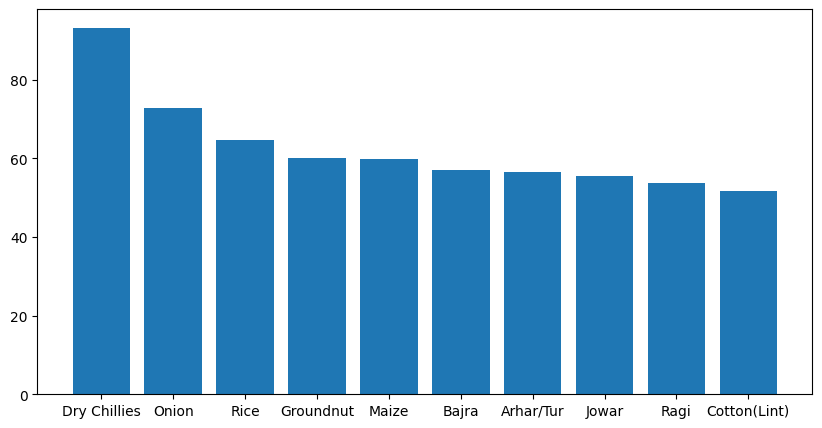

In [145]:
plt.figure(figsize=(10,5))

plt.bar(
    crop_results["Crop"].head(10),
    crop_results["Recommendation_Score"].head(10)
)

In [146]:
crop_results.to_csv(
    "../outputs/crop_results.csv",
    index=False
)